**BOSTON HOUSING - LINEAR REGRESSION**

First Five Rows:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  

Dataset Shape:
(506, 14)

Missing Values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         5
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Statistical Summary:
             CRIM          ZN       INDUS        CHAS         NOX          RM  \
count  506.

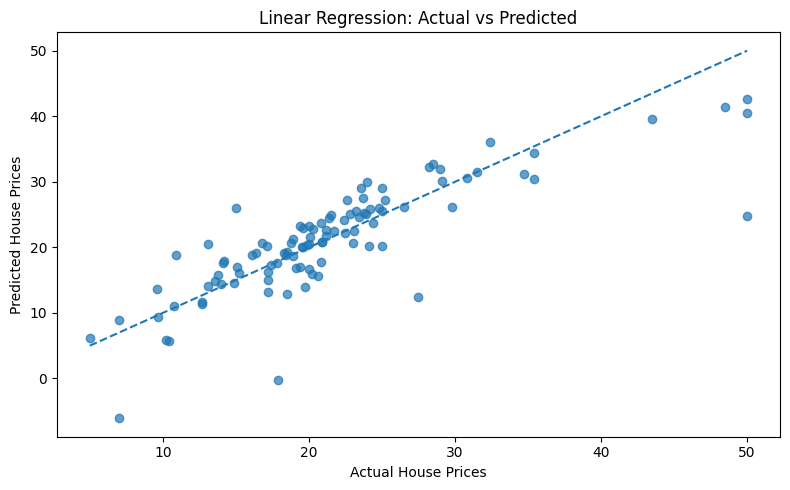

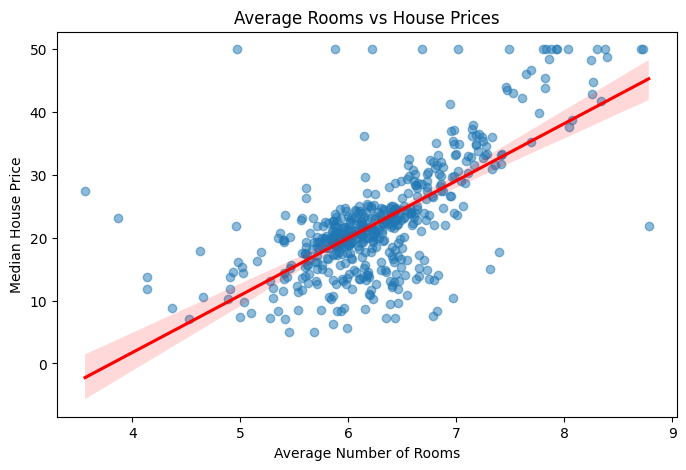

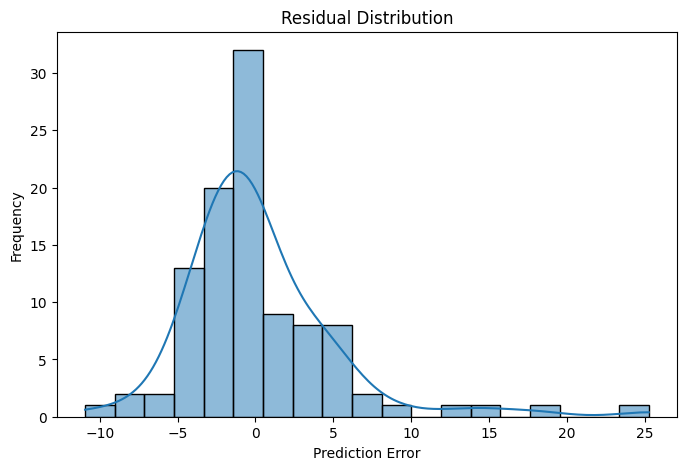

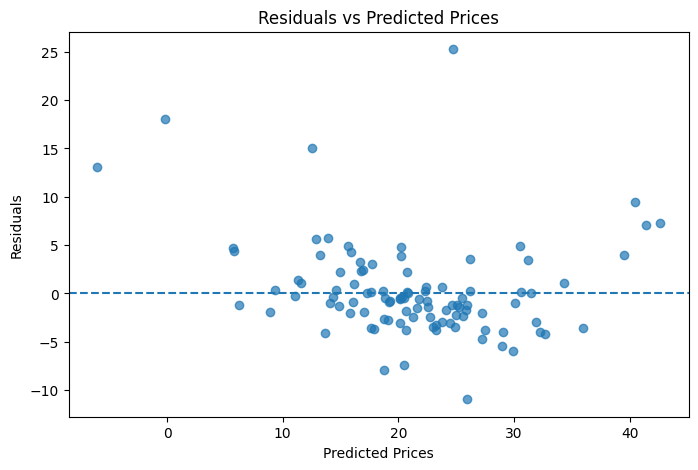


Linear Regression Completed Successfully!


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


df = pd.read_csv("/content/BostonHousing.csv")
df.columns = df.columns.str.strip().str.upper()

df = df.loc[:, ~df.columns.str.contains("^UNNAMED")]
df = df.drop(columns=["ID"], errors="ignore")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

# Data Preprocessing
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
df = df.drop_duplicates()

if "MEDV" not in df.columns:
    raise ValueError("MEDV column not found in dataset!")

df = df.dropna(subset=["MEDV"])

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

# Separate Features and Target

X = df.drop(columns=["MEDV"])
X = X.select_dtypes(include=np.number)

y = df["MEDV"]

if X.shape[1] == 0:
    raise ValueError("No numerical input features found!")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

# Create and Train Model

model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")

# Predictions

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nActual vs Predicted:")
print(results.head(10).round(2))

# Model Evaluation

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n===== LINEAR REGRESSION RESULTS =====")

print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

# Visualization 1
# Actual vs Predicted Prices

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Linear Regression: Actual vs Predicted")

plt.tight_layout()
plt.show()

# Visualization 2
# Regression Line: RM vs MEDV

if "RM" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.regplot(
        data=df,
        x="RM",
        y="MEDV",
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"}
    )

    plt.title("Average Rooms vs House Prices")
    plt.xlabel("Average Number of Rooms")
    plt.ylabel("Median House Price")

    plt.show()

# Visualization 3
# Residual Distribution

residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

# Visualization 4
# Residuals vs Predicted Values

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Prices")

plt.show()

print("\nLinear Regression Completed Successfully!")


 **BOSTON HOUSING - LOGISTIC REGRESSION (Binary Classification)**

First Five Rows:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  

Dataset Shape:
(506, 14)

Missing Values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         5
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Classification Threshold: 21.6

Class Labels:
0 = Low Price
1 = High Price

Training Class Distribution:
MEDV
1  

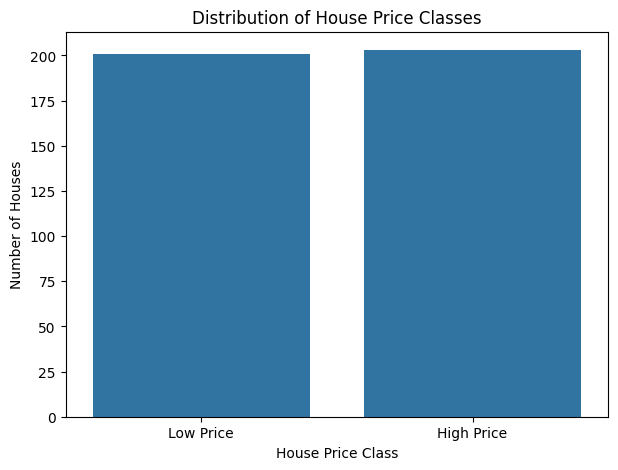

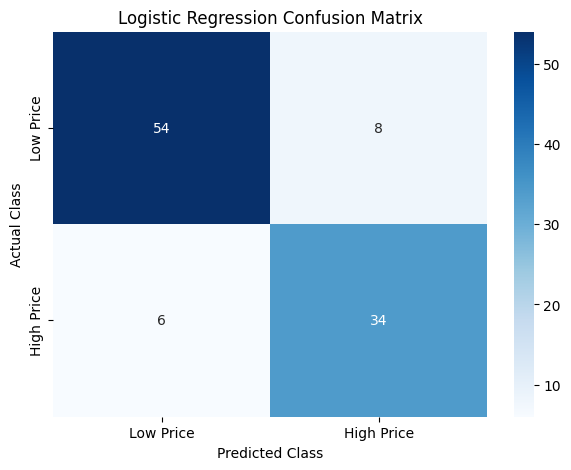

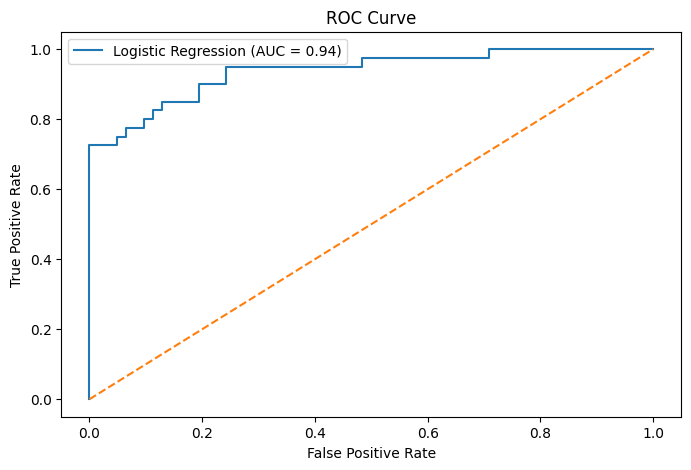


LOGISTIC REGRESSION COMPLETED!
Algorithm: Logistic Regression
Problem Type: Binary Classification
Target: House Price Category
Threshold: 21.6
Accuracy: 86.27 %
ROC AUC: 0.9371


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

df = pd.read_csv("/content/BostonHousing.csv")

df.columns = df.columns.str.strip().str.upper()

df = df.loc[:, ~df.columns.str.contains("^UNNAMED")]
df = df.drop(columns=["ID"], errors="ignore")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

# Data Preprocessing

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
df = df.drop_duplicates()

if "MEDV" not in df.columns:
    raise ValueError("MEDV column not found in dataset!")

df = df.dropna(subset=["MEDV"])

print("\nMissing Values:")
print(df.isnull().sum())

X = df.drop(columns=["MEDV"])
X = X.select_dtypes(include=np.number)

y = df["MEDV"]

if X.shape[1] == 0:
    raise ValueError("No numerical input features found!")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

price_threshold = y_train.median()

y_train_class = (
    y_train >= price_threshold
).astype(int)

y_test_class = (
    y_test >= price_threshold
).astype(int)

print("\nClassification Threshold:", price_threshold)

print("\nClass Labels:")
print("0 = Low Price")
print("1 = High Price")

print("\nTraining Class Distribution:")
print(y_train_class.value_counts())

# Building Logistic Regression Model

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

model.fit(X_train, y_train_class)

print("\nLogistic Regression Model Trained Successfully!")

y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual Class": y_test_class.values,
    "Predicted Class": y_pred,
    "High Price Probability": y_probability
})

print("\nActual vs Predicted Classes:")
print(results.head(10).round(3))

accuracy = accuracy_score(y_test_class, y_pred)

print("\n===== LOGISTIC REGRESSION RESULTS =====")

print("Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test_class,
        y_pred,
        labels=[0, 1],
        target_names=["Low Price", "High Price"],
        zero_division=0
    )
)

# Visualization 1
# Class Distribution

plt.figure(figsize=(7, 5))

sns.countplot(x=y_train_class)

plt.title("Distribution of House Price Classes")
plt.xlabel("House Price Class")
plt.ylabel("Number of Houses")

plt.xticks(
    [0, 1],
    ["Low Price", "High Price"]
)

plt.show()

# Visualization 2
# Confusion Matrix

cm = confusion_matrix(
    y_test_class,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Price", "High Price"],
    yticklabels=["Low Price", "High Price"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

# Visualization 3
# ROC Curve

fpr, tpr, thresholds = roc_curve(
    y_test_class,
    y_probability
)

auc = roc_auc_score(
    y_test_class,
    y_probability
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.show()

# STEP 13: Final Output

print("\n===================================")
print("LOGISTIC REGRESSION COMPLETED!")
print("===================================")

print("Algorithm: Logistic Regression")
print("Problem Type: Binary Classification")
print("Target: House Price Category")
print("Threshold:", price_threshold)
print("Accuracy:", round(accuracy * 100, 2), "%")
print("ROC AUC:", round(auc, 4))

print("===================================")
